# Phase, Symmetry, and Sound: Local U(1), Even/Odd Functions, and the 0–22 kHz Band

**Colin Casey, 2026.** SymPy for the analysis, Lean 4 for proofs, and the music and acoustics vocabulary that comes out of the same math.

| Part | Idea | Why it matters |
|---|---|---|
| 1 | **Global U(1):** multiply by $e^{i\alpha}$ | the phase a photodiode (or $\lvert\psi\rvert^2$) can't see; why GS needs `align_phase` |
| 2 | **Local U(1):** $e^{i\theta(x)}$, covariant derivative | how a phase that varies in space *forces* a field $A$ (electromagnetism) |
| 3 | **Complex analysis:** Cauchy-Riemann, winding number | phase on a circle, $\oint dz/z = 2\pi i$, why charge comes in whole units |
| 4 | **Even and odd functions** | cosines vs sines; odd × odd = even |
| 5 | **Synth waveforms** | square = odd harmonics only, saw = all, triangle = odd with 1/n² |
| 6 | **The 0–22 kHz band** | Nyquist at 44.1 kHz, octave bands, MIDI ↔ Hz, cents, dB SPL, a helicopter's blade-pass tone |
| 7 | **Vocabulary, minimum music knowledge, icebreakers** | for playing in a band and for acoustic engineering |
| 8 | **Lean 4 proofs** | even/odd algebra, phase composition mod 360°, octaves, harmonic counts |

Kernel: **py312**. Lean: `leanprover/lean4:v4.34.0-rc2`.

In [1]:
import subprocess, pathlib
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
sp.init_printing(use_latex='mathjax')
OI = ["#0072B2", "#D55E00", "#009E73", "#E69F00", "#CC79A7", "#56B4E9"]
plt.rcParams.update({'axes.prop_cycle': plt.cycler(color=OI), 'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
x, t = sp.symbols('x t', real=True)

---
## 1. Global U(1): the phase nobody can see

**In plain words.** U(1) is the set of rotations of a single complex number: multiply by $e^{i\alpha}$. Rotating *every* point by the same angle changes nothing you can measure, because measurements see $|\psi|^2$. That's the "global phase" every phase-retrieval notebook has to align away.

In [2]:
a, b, al = sp.symbols('a b alpha', real=True)
psi = a + sp.I*b
print('|e^{i alpha} psi|^2 - |psi|^2 =', sp.simplify(sp.Abs(sp.exp(sp.I*al)*psi)**2 - sp.Abs(psi)**2))
be = sp.symbols('beta', real=True)
print('group law: e^{i a} e^{i b} = e^{i(a+b)}:', sp.simplify(sp.exp(sp.I*al)*sp.exp(sp.I*be) - sp.exp(sp.I*(al + be))) == 0)
print('every element has an inverse: e^{i a} e^{-i a} =', sp.simplify(sp.exp(sp.I*al)*sp.exp(-sp.I*al)))

|e^{i alpha} psi|^2 - |psi|^2 = 0
group law: e^{i a} e^{i b} = e^{i(a+b)}: True
every element has an inverse: e^{i a} e^{-i a} = 1


---
## 2. Local U(1): when the phase varies from place to place

**In plain words.** Now let the angle depend on position: $\psi(x) \to e^{i\theta(x)}\psi(x)$. Values are still unaffected, but **derivatives** pick up an extra $i\theta'(x)$ term, so equations with $\partial_x$ (Schrödinger, kinetic energy) stop being symmetric. The fix is to add a field $A(x)$ and use the **covariant derivative**
$$D\psi = \left(\partial_x - iqA\right)\psi, \qquad \psi \to e^{i\theta}\psi,\quad A \to A + \tfrac{1}{q}\,\theta'(x)$$
Then $D\psi$ rotates exactly like $\psi$. The field that local phase symmetry *requires* is the electromagnetic potential, and $q$ is the charge. That's gauge theory in one line.

In [3]:
q = sp.symbols('q', positive=True)
th, ps, A = sp.Function('theta')(x), sp.Function('psi')(x), sp.Function('A')(x)
D = lambda f, Afield: sp.diff(f, x) - sp.I*q*Afield*f

psi_new = sp.exp(sp.I*th)*ps
A_new = A + sp.diff(th, x)/q
print('plain derivative is NOT covariant: d(e^{i th} psi) - e^{i th} dpsi =')
display(sp.simplify(sp.diff(psi_new, x) - sp.exp(sp.I*th)*sp.diff(ps, x)))
print('covariant derivative IS: D\'(psi\') - e^{i th} D(psi) =', sp.simplify(D(psi_new, A_new) - sp.exp(sp.I*th)*D(ps, A)))

# the field strength is gauge invariant in 1+1 D: F = dA_t/dx - dA_x/dt
At, Ax, chi = sp.Function('A_t')(x, t), sp.Function('A_x')(x, t), sp.Function('chi')(x, t)
F = lambda a_t, a_x: sp.diff(a_t, x) - sp.diff(a_x, t)
print('field strength unchanged by A -> A + grad(chi):', sp.simplify(F(At + sp.diff(chi, t), Ax + sp.diff(chi, x)) - F(At, Ax)) == 0)

plain derivative is NOT covariant: d(e^{i th} psi) - e^{i th} dpsi =


        ⅈ⋅θ(x) d       
ⅈ⋅ψ(x)⋅ℯ      ⋅──(θ(x))
               dx      

covariant derivative IS: D'(psi') - e^{i th} D(psi) = 0
field strength unchanged by A -> A + grad(chi): True


---
## 3. Complex analysis: phase lives on a circle

**In plain words.** $e^{z}$ is the nicest function there is: its real and imaginary parts satisfy the **Cauchy-Riemann** equations, which is what "complex-differentiable" means. Going once around the unit circle, $z = e^{it}$, the phase winds by $2\pi$, and the contour integral counts the turns:
$$\frac{1}{2\pi i}\oint \frac{dz}{z} = n \quad\text{(winding number, always a whole number)}$$
Because a phase that comes back to itself must wind a *whole* number of times, quantities tied to U(1) come in integers (flux quanta, the Dirac charge-quantization argument, vortices in superconductors).

In [4]:
X, Y = sp.symbols('X Y', real=True)
u, v = sp.exp(X)*sp.cos(Y), sp.exp(X)*sp.sin(Y)          # e^{X + iY}
print('Cauchy-Riemann for e^z: u_x - v_y =', sp.simplify(sp.diff(u, X) - sp.diff(v, Y)),
      ',  u_y + v_x =', sp.simplify(sp.diff(u, Y) + sp.diff(v, X)))
print('|e^{i t}| =', sp.simplify(sp.Abs(sp.exp(sp.I*t))))

n = sp.symbols('n', integer=True, nonzero=True)
zc = sp.exp(sp.I*n*t)                                     # a loop that winds n times
winding = sp.simplify(sp.integrate(sp.diff(zc, t)/zc, (t, 0, 2*sp.pi)) / (2*sp.pi*sp.I))
print('winding number of e^{i n t} around 0:', winding)
z = sp.symbols('z')
print('residue of 1/z at 0:', sp.residue(1/z, z, 0), ' -> oint dz/z = 2 pi i')

Cauchy-Riemann for e^z: u_x - v_y = 0 ,  u_y + v_x = 0
|e^{i t}| = 1
winding number of e^{i n t} around 0: n
residue of 1/z at 0: 1  -> oint dz/z = 2 pi i


---
## 4. Even and odd functions

**In plain words.** A function is **even** if it looks the same in a mirror, $f(-x) = f(x)$ (like $\cos$, $x^2$), and **odd** if the mirror flips its sign, $f(-x) = -f(x)$ (like $\sin$, $x^3$). Every function splits uniquely into the two:
$$f(x) = \underbrace{\tfrac12\left[f(x) + f(-x)\right]}_{\text{even}} + \underbrace{\tfrac12\left[f(x) - f(-x)\right]}_{\text{odd}}$$
Rules of thumb: odd × odd = even, even × odd = odd, and the integral of an odd function over $[-L, L]$ is 0. That last rule is why Fourier series of even signals contain only cosines and of odd signals only sines.

In [5]:
f = sp.exp(x)
fe, fo = (f + f.subs(x, -x))/2, (f - f.subs(x, -x))/2
display(sp.Eq(sp.Symbol('even part of e^x'), fe.rewrite(sp.cosh).simplify()), sp.Eq(sp.Symbol('odd part of e^x'), fo.rewrite(sp.sinh).simplify()))
print('sin(x)*sin(3x) is even:', sp.simplify((sp.sin(x)*sp.sin(3*x)).subs(x, -x) - sp.sin(x)*sp.sin(3*x)) == 0)
print('integral of x^3 cos(x) over [-pi, pi] (odd):', sp.integrate(x**3*sp.cos(x), (x, -sp.pi, sp.pi)))

even part of e__x = cosh(x)

odd part of e__x = sinh(x)

sin(x)*sin(3x) is even: True


integral of x^3 cos(x) over [-pi, pi] (odd): 0


---
## 5. Synth waveforms: symmetry decides the harmonics

**In plain words.** A synthesizer oscillator's *timbre* is its list of harmonics. Symmetry decides that list:
- **Square wave**: odd in time *and* half-wave symmetric, so **odd harmonics only**, amplitudes $1/n$. Sounds hollow, woody (clarinet-like).
- **Sawtooth**: odd, but no half-wave symmetry, so **every harmonic**, $1/n$. Bright, buzzy (brass, strings, the classic synth lead).
- **Triangle**: even (as drawn here), **odd harmonics only**, $1/n^2$, so they fade fast. Soft, flute-like, close to a sine.

In [6]:
sq = sp.fourier_series(sp.Piecewise((-1, x < 0), (1, True)), (x, -sp.pi, sp.pi))
sw = sp.fourier_series(x, (x, -sp.pi, sp.pi))
tr = sp.fourier_series(sp.Abs(x), (x, -sp.pi, sp.pi))
for name, s in (('square', sq), ('sawtooth', sw), ('triangle', tr)):
    display(sp.Eq(sp.Symbol(name), s.truncate(4)))

         4⋅sin(x)   4⋅sin(3⋅x)   4⋅sin(5⋅x)   4⋅sin(7⋅x)
square = ──────── + ────────── + ────────── + ──────────
            π          3⋅π          5⋅π          7⋅π    

                                 2⋅sin(3⋅x)   sin(4⋅x)
sawtooth = 2⋅sin(x) - sin(2⋅x) + ────────── - ────────
                                     3           2    

             4⋅cos(x)   4⋅cos(3⋅x)   4⋅cos(5⋅x)   π
triangle = - ──────── - ────────── - ────────── + ─
                π          9⋅π          25⋅π      2

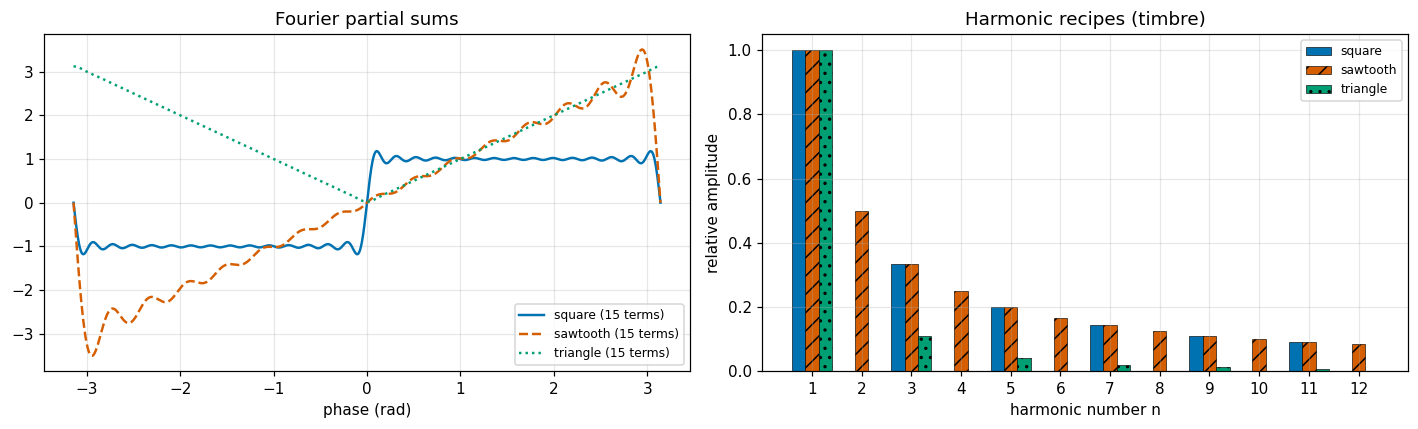

Figure: left, the three waveforms built from 15 Fourier terms (square has ripple at its jumps, the Gibbs effect). Right, harmonic amplitudes relative to the fundamental: square and triangle have bars only at odd n, and the triangle bars shrink much faster; the sawtooth has a bar at every n.


In [7]:
xs = np.linspace(-np.pi, np.pi, 2000)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
styles = ['-', '--', ':']
for (name, s), ls in zip((('square', sq), ('sawtooth', sw), ('triangle', tr)), styles):
    ax[0].plot(xs, sp.lambdify(x, s.truncate(15), 'numpy')(xs), ls, lw=1.6, label=f'{name} (15 terms)')
ax[0].set_xlabel('phase (rad)'); ax[0].set_title('Fourier partial sums'); ax[0].legend(fontsize=8)
nn = np.arange(1, 13)
amp = {'square': np.where(nn % 2 == 1, 1/nn, 0), 'sawtooth': 1/nn, 'triangle': np.where(nn % 2 == 1, 1/nn**2, 0)}
for i, (name, a_n) in enumerate(amp.items()):
    ax[1].bar(nn + (i - 1)*0.27, a_n/a_n[0], width=0.27, label=name, hatch=['', '//', '..'][i], edgecolor='k', lw=0.4)
ax[1].set_xlabel('harmonic number n'); ax[1].set_ylabel('relative amplitude'); ax[1].set_xticks(nn); ax[1].legend(fontsize=8)
ax[1].set_title('Harmonic recipes (timbre)')
plt.tight_layout(); plt.show()
print('Figure: left, the three waveforms built from 15 Fourier terms (square has ripple at its jumps, the Gibbs '
      'effect). Right, harmonic amplitudes relative to the fundamental: square and triangle have bars only at odd n, '
      'and the triangle bars shrink much faster; the sawtooth has a bar at every n.')

---
## 6. The 0–22 kHz band

**In plain words.** People hear roughly 20 Hz to 20 kHz (less with age). CD and most streaming audio sample at **44.1 kHz**, so the highest representable frequency is the **Nyquist limit, 22,050 Hz**; a bright sawtooth's harmonics above that fold back as aliasing (the same effect as in the v9 prototype). Pitch is logarithmic: an **octave** doubles the frequency, a **semitone** multiplies by $2^{1/12}$, and **MIDI note** $m$ has
$$f = 440\cdot 2^{(m - 69)/12}\ \text{Hz}, \qquad \text{cents} = 1200\log_2\frac{f_2}{f_1}, \qquad L_p = 20\log_{10}\frac{p}{20\ \mu\text{Pa}}\ \text{dB SPL}$$

In [8]:
m = sp.symbols('m', integer=True)
f_midi = 440*2**((m - 69)/sp.Integer(12))
display(sp.Eq(sp.Symbol('f(m)'), f_midi))
notes = {'E1 (bass low E)': 28, 'A2': 45, 'C4 (middle C)': 60, 'A4 (tuning)': 69, 'C8 (top of piano)': 108}
fs_audio = 44100; nyq = fs_audio/2
print(f'{"note":18s} {"f (Hz)":>9s} {"saw harmonics < Nyquist":>24s} {"square harmonics":>17s}')
for name, mm in notes.items():
    f0 = float(f_midi.subs(m, mm)); N = int(nyq // f0)
    print(f'{name:18s} {f0:9.2f} {N:24d} {(N + 1)//2:17d}')
print('\none semitone =', sp.N(1200*sp.log(2**(sp.Integer(1)/12), 2)), 'cents;  a 1 Hz error at A4 is',
      round(float(1200*sp.log(441/sp.Integer(440), 2)), 2), 'cents')
print('dB SPL: 1 Pa =', round(float(20*sp.log(1/sp.Float(20e-6), 10)), 1), 'dB;  doubling pressure = +6.02 dB;  doubling power = +3.01 dB')

            m    23
            ── - ──
            12   4 
f(m) = 440⋅2       

note                  f (Hz)  saw harmonics < Nyquist  square harmonics
E1 (bass low E)        41.20                      535               268
A2                    110.00                      200               100
C4 (middle C)         261.63                       84                42
A4 (tuning)           440.00                       50                25
C8 (top of piano)    4186.01                        5                 3

one semitone = 100.000000000000 cents;  a 1 Hz error at A4 is 3.93 cents
dB SPL: 1 Pa = 94.0 dB;  doubling pressure = +6.02 dB;  doubling power = +3.01 dB


In [9]:
bands = [('sub-bass', 20, 60), ('bass', 60, 250), ('low mids', 250, 500), ('mids', 500, 2000),
         ('upper mids', 2000, 4000), ('presence', 4000, 6000), ('brilliance / air', 6000, 20000)]
print(f'{"band":17s} {"range (Hz)":>15s}   what lives there')
what = ['kick drum thump, felt more than heard', 'bass guitar, kick body, warmth', 'muddiness if too much',
        'vocals, guitars, the "body" of most instruments', 'intelligibility, attack, ear is most sensitive here',
        'definition, consonants, sibilance starts', 'cymbals, breath, sparkle']
for (bname, lo, hi), w in zip(bands, what):
    print(f'{bname:17s} {lo:>6d} - {hi:<7d}   {w}')
exact = [1000*2**k for k in range(-5, 5)]
print('\noctave-band centres, exact 1000 x 2^k (Hz):', [round(c, 2) for c in exact])
print('ISO 266 nominal labels (Hz):              ', [31.5, 63, 125, 250, 500, 1000, 2000, 4000, 8000, 16000])

band                   range (Hz)   what lives there
sub-bass              20 - 60        kick drum thump, felt more than heard
bass                  60 - 250       bass guitar, kick body, warmth
low mids             250 - 500       muddiness if too much
mids                 500 - 2000      vocals, guitars, the "body" of most instruments
upper mids          2000 - 4000      intelligibility, attack, ear is most sensitive here
presence            4000 - 6000      definition, consonants, sibilance starts
brilliance / air    6000 - 20000     cymbals, breath, sparkle

octave-band centres, exact 1000 x 2^k (Hz): [31.25, 62.5, 125.0, 250.0, 500.0, 1000, 2000, 4000, 8000, 16000]
ISO 266 nominal labels (Hz):               [31.5, 63, 125, 250, 500, 1000, 2000, 4000, 8000, 16000]


### Example: a helicopter's "whop"

The thump of a helicopter is the **blade-pass frequency** $f_{BP} = N_{blades}\times\text{RPM}/60$ and its harmonics. With illustrative numbers (4-blade main rotor at 258 rpm, 2-blade tail rotor at 1,300 rpm), the main-rotor fundamental is *below* hearing; you hear its harmonics and the tail rotor.

In [10]:
for name, blades, rpm in (('main rotor', 4, 258), ('tail rotor', 2, 1300)):
    fbp = blades*rpm/60
    print(f'{name}: f_BP = {blades} x {rpm}/60 = {fbp:.1f} Hz;  harmonics: ' + ', '.join(f'{k*fbp:.0f}' for k in range(1, 6)) + ' Hz')
print('(illustrative values; real rotors vary by aircraft)')

main rotor: f_BP = 4 x 258/60 = 17.2 Hz;  harmonics: 17, 34, 52, 69, 86 Hz
tail rotor: f_BP = 2 x 1300/60 = 43.3 Hz;  harmonics: 43, 87, 130, 173, 217 Hz
(illustrative values; real rotors vary by aircraft)


---
## 7. Vocabulary for playing in a band, and the minimum music knowledge for acoustic engineering

### Synth and sound vocabulary
| Term | Meaning | The math underneath |
|---|---|---|
| oscillator | the tone source (sine, saw, square, triangle) | periodic function, Fourier series |
| timbre | the "colour" of a sound | the harmonic amplitudes (section 5) |
| filter, cutoff, resonance | removes highs (low-pass) above a cutoff; resonance boosts near it | transfer function H(f), poles |
| ADSR envelope | Attack, Decay, Sustain, Release: loudness over time | piecewise exponentials e^{-t/τ} |
| LFO | a slow oscillator (< 20 Hz) that wobbles pitch, volume or cutoff | modulation |
| detune, unison, chorus | several slightly mistuned copies, beating against each other | cos a + cos b → beats at \|f₁ − f₂\| |
| ring modulation / AM | multiply two signals: makes sum and difference tones | cos a cos b = ½[cos(a−b) + cos(a+b)] |
| FM synthesis | wobble the frequency fast: many sidebands | Bessel functions |
| frequency shifter | moves every partial by the same Hz (not musical intervals) | multiply the analytic signal by $e^{i\omega t}$: a U(1) rotation |
| sample rate, Nyquist, aliasing | 44.1 kHz → nothing above 22.05 kHz; higher partials fold back | section 6, prototype v9 |
| gain, headroom, clipping | level vs the maximum before distortion | dB, saturating nonlinearity (adds odd harmonics if symmetric) |
| EQ | boost or cut frequency bands | section 6 band table |

### Minimum music knowledge for acoustic engineering
1. **Pitch is logarithmic:** octave = ×2, semitone = ×2^{1/12}, cents for small errors; A4 = 440 Hz.
2. **Notes, scales, intervals:** 12 pitch classes; a perfect fifth ≈ ×1.5 (7 semitones), a major third ≈ ×1.26 (4 semitones).
3. **Harmonics and timbre:** every instrument is a fundamental plus a harmonic recipe; strings and brass have all harmonics, a clarinet mostly odd ones.
4. **Loudness in dB:** SPL re 20 µPa; +6 dB = double pressure, +10 dB ≈ "twice as loud" perceptually; equal-loudness (Fletcher-Munson) curves, A-weighting.
5. **Instrument ranges:** bass ~41 Hz to ~400 Hz, guitar ~82 Hz to ~1.2 kHz fundamentals, voice ~85 Hz to ~1.1 kHz, cymbals up to 15 kHz+.
6. **Rhythm and tempo:** BPM; one beat at 120 BPM = 0.5 s; delay times are set in beats.
7. **Room acoustics:** reverberation time (RT60), standing waves (room modes at c/2L), absorption vs diffusion.
8. **Signal chain:** microphone → preamp → ADC → DAW → DAC → amp → speaker, and where noise and distortion enter.

### Icebreaker questions for a band
- What's the first song you ever learned to play, and do you still remember it?
- Which one sound (an instrument, a synth patch, a voice) makes you instantly happy?
- If our band could only use three chords forever, which three?
- Analog or digital: what's one piece of gear you'd never sell?
- What song do you think is overrated, and which one is criminally underrated?
- What's the strangest place you've ever played or heard live music?
- Odd or even time signature for our first original song: 4/4, 7/8, or 5/4?

---
## 8. Lean 4 proofs

Exact facts behind sections 1–6, checked by the Lean kernel (core Lean, integer functions so no Mathlib is needed):
- odd × odd = even, even × odd = odd; every function splits into even + odd parts;
- U(1) phases in whole degrees compose by addition mod 360;
- 12 semitones up is the same pitch class;
- a 440 Hz sawtooth has 50 harmonics under 22,050 Hz; a square wave's first five harmonics are 1, 3, 5, 7, 9.

In [11]:
LEAN_SRC = r'''
-- generated by u1_symmetry_even_odd_sound.ipynb (core Lean 4, no Mathlib)
def IsEven (f : Int → Int) : Prop := ∀ x, f (-x) = f x
def IsOdd (f : Int → Int) : Prop := ∀ x, f (-x) = - f x

-- odd × odd = even  (e.g. sin·sin),  even × odd = odd  (e.g. cos·sin)
theorem odd_mul_odd (f g : Int → Int) (hf : IsOdd f) (hg : IsOdd g) :
    IsEven (fun x => f x * g x) := by
  intro x
  simp only [hf x, hg x, Int.neg_mul_neg]

theorem even_mul_odd (f g : Int → Int) (hf : IsEven f) (hg : IsOdd g) :
    IsOdd (fun x => f x * g x) := by
  intro x
  simp only [hf x, hg x, Int.mul_neg]

-- every function splits into an even part and an odd part (scaled by 2 to stay in Int)
theorem even_part_even (f : Int → Int) : IsEven (fun x => f x + f (-x)) := by
  intro x
  simp only [Int.neg_neg]
  omega

theorem odd_part_odd (f : Int → Int) : IsOdd (fun x => f x - f (-x)) := by
  intro x
  simp only [Int.neg_neg]
  omega

theorem even_odd_split (f : Int → Int) (x : Int) :
    2 * f x = (f x + f (-x)) + (f x - f (-x)) := by omega

-- U(1) in integer degrees: composing phase rotations is addition mod 360
theorem phase_compose (a b : Nat) : (a + b) % 360 = (a % 360 + b % 360) % 360 := Nat.add_mod a b 360

-- music: 12 semitones up lands on the same pitch class (an octave)
theorem octave (n : Nat) : (n + 12) % 12 = n % 12 := Nat.add_mod_right n 12

-- a 440 Hz sawtooth fits 50 harmonics below the 22,050 Hz Nyquist limit of 44.1 kHz audio
theorem harmonics_A4 : 22050 / 440 = 50 := by decide

-- a square wave uses only odd harmonics: the first five are 1, 3, 5, 7, 9
theorem square_odd_harmonics :
    (List.range 10).filter (fun n => n % 2 = 1) = [1, 3, 5, 7, 9] := by decide
'''

lean_file = pathlib.Path.cwd() / 'u1_symmetry_even_odd_sound.lean'
lean_file.write_text(LEAN_SRC.strip() + '\n', encoding='utf-8')
print(LEAN_SRC.strip())
r = subprocess.run(['lean', '+leanprover/lean4:v4.34.0-rc2', str(lean_file)], capture_output=True, text=True)
print(f'\n{lean_file.name}: exit code {r.returncode};', LEAN_SRC.count('theorem '), 'theorems')
print((r.stdout + r.stderr).strip() or 'no errors: every theorem verified by the Lean kernel')

-- generated by u1_symmetry_even_odd_sound.ipynb (core Lean 4, no Mathlib)
def IsEven (f : Int → Int) : Prop := ∀ x, f (-x) = f x
def IsOdd (f : Int → Int) : Prop := ∀ x, f (-x) = - f x

-- odd × odd = even  (e.g. sin·sin),  even × odd = odd  (e.g. cos·sin)
theorem odd_mul_odd (f g : Int → Int) (hf : IsOdd f) (hg : IsOdd g) :
    IsEven (fun x => f x * g x) := by
  intro x
  simp only [hf x, hg x, Int.neg_mul_neg]

theorem even_mul_odd (f g : Int → Int) (hf : IsEven f) (hg : IsOdd g) :
    IsOdd (fun x => f x * g x) := by
  intro x
  simp only [hf x, hg x, Int.mul_neg]

-- every function splits into an even part and an odd part (scaled by 2 to stay in Int)
theorem even_part_even (f : Int → Int) : IsEven (fun x => f x + f (-x)) := by
  intro x
  simp only [Int.neg_neg]
  omega

theorem odd_part_odd (f : Int → Int) : IsOdd (fun x => f x - f (-x)) := by
  intro x
  simp only [Int.neg_neg]
  omega

theorem even_odd_split (f : Int → Int) (x : Int) :
    2 * f x = (f x + f (-x)) + (f x - f (


u1_symmetry_even_odd_sound.lean: exit code 0; 9 theorems
no errors: every theorem verified by the Lean kernel


## Going further
- **Real and complex analysis in Lean** (limits, $e^{i\theta}$ on ℂ, contour integrals) needs **Mathlib**: `lake new u1 math`, then `Complex.exp`, `Complex.abs_exp_ofReal_mul_I`, and the circle integral `circleIntegral`.
- **Gauge theory next step:** the Aharonov-Bohm phase $q\oint A\,dx$, the U(1) twin of the winding number in section 3.
- **Audio next step:** synthesize the three waveforms at 44.1 kHz and listen to aliasing appear as the pitch rises.